# 01 · Что в данных помогает различать исходы цирроза

Одна строка описывает синтетическую запись пациента. В момент обследования известны возраст, назначенный препарат, результаты осмотра, лабораторные показатели и стадия. По ним предстоит оценить три вероятности. Класс `C` означает, что наблюдение завершилось без зарегистрированной смерти или трансплантации, `CL` — наблюдение завершилось трансплантацией печени, `D` — зарегистрирована смерть. У записей разные сроки наблюдения, поэтому по этим меткам нельзя определить, например, годовую выживаемость.

В основе работы лежат два разбора одного соревнования. Здесь они сведены в один маршрут от проверки таблиц до выбора признаков для моделирования. Все таблицы и рисунки рассчитаны заново. [Данные Kaggle](https://www.kaggle.com/competitions/playground-series-s3e26/data) · [Словарь первичного исследования UCI](https://archive.ics.uci.edu/dataset/878/cirrhosis+patient+survival+prediction)

### Что дали два исходных ноутбука

| Вопрос | Что было в начале работы | Что вошло в объединённую версию |
|---|---|---|
| Как читать таблицу | Оба файла описывают структуру, классы, распределения и выбросы. В GitHub EDA есть словарь, пересчёт возраста и сравнение с логарифмом. | Один словарь и одна проверка каждого свойства. Дни сохранены для поиска точных совпадений, годы используются для интерпретации. |
| С чем связан исход | В `main.ipynb` есть доли по категориям, ранговые связи, сочетания признаков и время наблюдения. В GitHub EDA есть критерий χ² для смерти. | Сопоставляем все три класса, размер связи и частоты групп. Отдельно проверяем, сколько информации добавляет второй признак. |
| Можно ли переносить результаты | В `main.ipynb` есть сравнение train и test и оценка по одному признаку. В GitHub EDA поставлен вопрос о повторных профилях. | Проверяем точность признаков при группировке, учим границы интервалов внутри фолда и явно отделяем срок наблюдения от входных данных. |

Предоставленный `main.ipynb` и [EDA из ветки Nikhat-DA](https://github.com/PavelK210/pbp-cirrhosis/blob/d45aa4cce28434bc59395feca82fd4b78887b77d/notebooks/EDA.ipynb) — источники начального анализа. Продолжение эксперимента находится в `02_modeling.ipynb`.

## 1. Что измерено в одной строке

Kaggle сгенерировал таблицы на основе исходного набора о первичном билиарном циррозе. Реестр UCI описывает 418 исходных участников. Из этого числа нельзя восстановить, какой участник послужил источником синтетической строки.

| Поля в CSV | Как читать значения |
|---|---|
| `id`, `Status`, `N_Days` | Номер строки, зарегистрированный исход и дни от регистрации до события или окончания наблюдения. |
| `Age`, `Sex`, `Drug` | Возраст в днях, пол и назначение D-пеницилламина либо плацебо. |
| `Ascites`, `Hepatomegaly`, `Spiders` | Признаки асцита, увеличенной печени и сосудистых звёздочек (`Y/N`). |
| `Edema`, `Stage` | Отёки (`N` — отсутствуют без терапии, `S` — есть без диуретиков либо устранены ими, `Y` — сохраняются при терапии) и гистологическая стадия 1–4. |
| `Bilirubin`, `Cholesterol`, `Albumin` | Билирубин и холестерин (мг/дл), альбумин (г/дл). |
| `Copper`, `Alk_Phos`, `SGOT` | Медь в суточной моче (мкг/сут), щелочная фосфатаза (ед/л), активность SGOT (ед/мл по словарю). |
| `Tryglicerides`, `Platelets`, `Prothrombin` | Триглицериды (мг/дл, написание столбца сохранено), тромбоциты и протромбиновое время (секунды). |

В `train.csv` известен исход. В `test.csv` есть только признаки. Файл `sample_submission.csv` задаёт порядок строк и столбцов для прогноза. [Описание данных](https://www.kaggle.com/competitions/playground-series-s3e26/data) · [Значения полей](https://archive.ics.uci.edu/dataset/878/cirrhosis+patient+survival+prediction)

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from scipy.stats import chi2_contingency, false_discovery_control
from sklearn.metrics import log_loss

from study_data import CATEGORICAL, CLASSES, COLORS, LABS, LOG_LABS, PROFILE, partition, profile_ids, read_inputs

plt.rcParams.update({"figure.dpi": 105, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlelocation": "left", "font.size": 10})
train, test, sample = read_inputs()
dev, control, folds = partition(train)
print(f"Train {train.shape} · test {test.shape} · шаблон {sample.shape}")
display(train.head(3))

Train (7905, 20) · test (5271, 19) · шаблон (5271, 4)


,id,N_Days,Drug,Age,Sex,Ascites,Hepatomegaly,Spiders,Edema,Bilirubin,Cholesterol,Albumin,Copper,Alk_Phos,SGOT,Tryglicerides,Platelets,Prothrombin,Stage,Status
0,0,999,D-penicillamine,21532,M,N,N,N,N,2.3,316.0,3.35,172.0,1601.0,179.80,63.0,394.0,9.7,3.0,D
1,1,2574,Placebo,19237,F,N,N,N,N,0.9,364.0,3.54,63.0,1440.0,134.85,88.0,361.0,11.0,3.0,C
2,2,3428,Placebo,13727,F,N,Y,Y,Y,3.3,299.0,3.55,131.0,1029.0,119.35,50.0,199.0,11.7,4.0,D


### 1.1. Пропуски, диапазоны и повторяющиеся профили

Совпадение по `id` и совпадение по измерениям отвечают на разные вопросы. Номер уникален по построению. Проверим значения без номера и метки, затем уберём и `N_Days`. Именно по оставшимся 17 полям модель будет различать записи. Пустые ячейки считаются до каких-либо преобразований.

In [3]:
schema = pd.DataFrame({
    "тип train": train.dtypes.astype(str), "уровней в train": train.nunique(),
    "пропуски train": train.isna().sum(), "пропуски test": test.isna().sum().astype("Int64"),
})
display(schema)
assert train.Age.gt(0).all() and test.Age.gt(0).all()
for frame in (train, test):
    assert set(frame.Stage.dropna()).issubset({1, 2, 3, 4})
    assert frame[LABS + ["N_Days"]].gt(0).all().all()
display(train[["Age", *LABS, "N_Days"]].agg(["min", "median", "max"]).T)

def duplicate_counts(frame):
    repeated = frame.duplicated(keep=False)
    return [frame.duplicated().sum(), repeated.sum(), len(frame[repeated].drop_duplicates())]

rounded = train[PROFILE].assign(Age=(train.Age / 365.25).round(1))
audit = pd.DataFrame.from_dict({
    "Train · все поля без id": duplicate_counts(train.drop(columns="id")),
    "Train · доступное при обследовании + срок": duplicate_counts(train[[*PROFILE, "N_Days"]]),
    "Train · точные 17 признаков": duplicate_counts(train[PROFILE]),
    "Train · возраст округлён до 0,1 года": duplicate_counts(rounded),
    "Test · точные 17 признаков": duplicate_counts(test[PROFILE]),
}, orient="index", columns=["лишних строк", "всего строк в группах", "повторяющихся групп"])
display(audit)
profiles = profile_ids(train)
conflicts = train.groupby(profiles).Status.nunique().gt(1).sum()
common_rows = test[PROFILE].merge(train[PROFILE].drop_duplicates(), on=PROFILE, how="inner")
print(f"Профилей train с разными метками: {conflicts}. Строк test с профилем из train: {len(common_rows)}.")

,тип train,уровней в train,пропуски train,пропуски test
Age,int64,391,0,0
Albumin,float64,160,0,0
Alk_Phos,float64,364,0,0
Ascites,str,2,0,0
Bilirubin,float64,111,0,0
Cholesterol,float64,226,0,0
Copper,float64,171,0,0
Drug,str,2,0,0
Edema,str,3,0,0
Hepatomegaly,str,2,0,0


,min,median,max
Age,9598.00,18713.00,28650.00
Bilirubin,0.30,1.10,28.00
Cholesterol,120.00,298.00,1775.00
Albumin,1.96,3.58,4.64
Copper,4.00,63.00,588.00
Alk_Phos,289.00,1181.00,13862.40
SGOT,26.35,108.50,457.25
Tryglicerides,33.00,104.00,598.00
Platelets,62.00,265.00,563.00
Prothrombin,9.00,10.60,18.00


,лишних строк,всего строк в группах,повторяющихся групп
Train · все поля без id,0,0,0
Train · доступное при обследовании + срок,0,0,0
Train · точные 17 признаков,5,10,5
"Train · возраст округлён до 0,1 года",7,14,7
Test · точные 17 признаков,2,4,2


Профилей train с разными метками: 1. Строк test с профилем из train: 5.


В train и test нет пропусков. Среди исходных профилей train совпали пять пар. Если сначала округлить возраст до десятых года, получатся семь пар из GitHub EDA. Для разбиения сохраняем возраст в днях. У одной группы совпадающих измерений встречаются разные исходы, поэтому удаление «лишней» строки могло бы скрыть настоящую неоднозначность. Совпадение синтетических профилей также не позволяет установить личность пациента.

### 1.2. Какие строки участвуют в исследовании связей

На полном train сверяем структуру и общий состав. Дальше исходы сопоставляем с признаками только на **выборке разработки**. Около пятой части размеченных строк отложено для итоговой проверки моделей. Группа одинаковых профилей целиком попадает в одну часть. Внутри разработки действуют ещё пять таких же групповых стратифицированных фолдов. Оба ноутбука вызывают одну функцию разбиения.

In [4]:
print(f"Разработка: {len(dev)} строк. Итоговый контроль: {len(control)} строк.")
assert not set(pd.MultiIndex.from_frame(dev[PROFILE])).intersection(pd.MultiIndex.from_frame(control[PROFILE]))

Разработка: 6324 строк. Итоговый контроль: 1581 строк.


## 2. Почему для трансплантации нужна отдельная оценка

Доля класса задаёт отправную вероятность, когда о строке ничего больше не известно. Сравним число наблюдений и средний штраф за прогноз по частотам. При multiclass log loss строка с вероятностью истинного исхода `p` вносит `−ln(p)`. Чем меньше средний штраф, тем лучше вероятности.

,строк train,"доля train, %",строк в разработке
Status,,,
C,4965,62.81,3972
CL,275,3.48,220
D,2665,33.71,2132


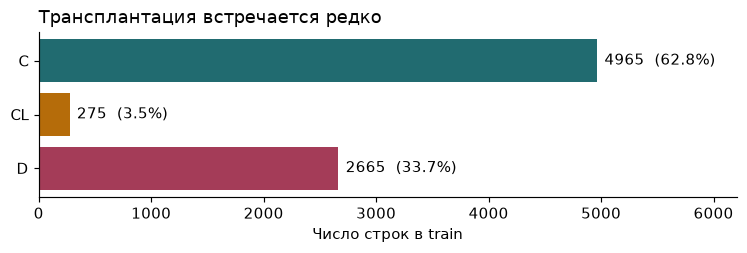

Штраф по частотам всего train: 0.776. Одна строка при p=0,05 даёт 3.00, при p=0,8 — 0.22.


In [5]:
counts = train.Status.value_counts().reindex(CLASSES)
freq = counts / counts.sum()
targets = pd.DataFrame({"строк train": counts, "доля train, %": freq * 100,
                        "строк в разработке": dev.Status.value_counts().reindex(CLASSES)})
display(targets.round(2))
fig, ax = plt.subplots(figsize=(7, 2.3), layout="constrained")
bars = ax.barh(CLASSES, counts, color=[COLORS[c] for c in CLASSES])
ax.bar_label(bars, labels=[f"{n}  ({p:.1%})" for n, p in zip(counts, freq)], padding=5)
ax.set(xlabel="Число строк в train", title="Трансплантация встречается редко", xlim=(0, counts.max()*1.25))
ax.invert_yaxis()
plt.show()
print(f"Штраф по частотам всего train: {-(freq * np.log(freq)).sum():.3f}. "
      f"Одна строка при p=0,05 даёт {-np.log(.05):.2f}, при p=0,8 — {-np.log(.8):.2f}.")

В train всего 275 строк `CL`, примерно одна на 29. Классификатор, всегда выбирающий `C`, угадает около 63% меток и пропустит каждую трансплантацию. Поэтому в продолжении будем смотреть и на вероятности всех исходов, и отдельно на полноту и точность поиска `CL`. Частотную модель для сравнения каждый раз обучим на своей обучающей части.

## 3. Что меняют длинные хвосты

### 3.1. Форма распределений и преобразование `log1p`

Билирубин и некоторые другие показатели занимают широкий диапазон. Для линейной модели одинаковая абсолютная прибавка всегда даёт одинаковое изменение логарифма шансов. Логарифм позволяет той же модели сильнее различать малые значения. Сопоставим исходную шкалу и `ln(1+x)` для шести кандидатов из начального анализа.

,min,25%,50%,mean,75%,max,асимметрия,после log1p
Age_years,26.28,42.71,51.25,50.41,56.63,78.44,0.07,NaN
Bilirubin,0.30,0.70,1.10,2.60,3.00,28.00,3.36,1.43
Cholesterol,120.00,248.00,299.00,350.86,390.00,1775.00,3.66,1.25
Albumin,1.96,3.35,3.59,3.55,3.77,4.64,-0.57,NaN
Copper,4.00,39.00,63.00,84.38,102.00,588.00,2.63,0.04
Alk_Phos,289.00,834.00,1190.00,1828.74,1860.00,13862.40,3.17,1.00
SGOT,26.35,75.95,108.50,114.83,137.95,457.25,1.51,0.01
Tryglicerides,33.00,84.00,104.00,115.27,139.00,598.00,2.62,0.38
Platelets,62.00,212.00,265.00,265.47,316.00,563.00,0.41,NaN
Prothrombin,9.00,10.00,10.60,10.63,11.00,18.00,1.38,NaN


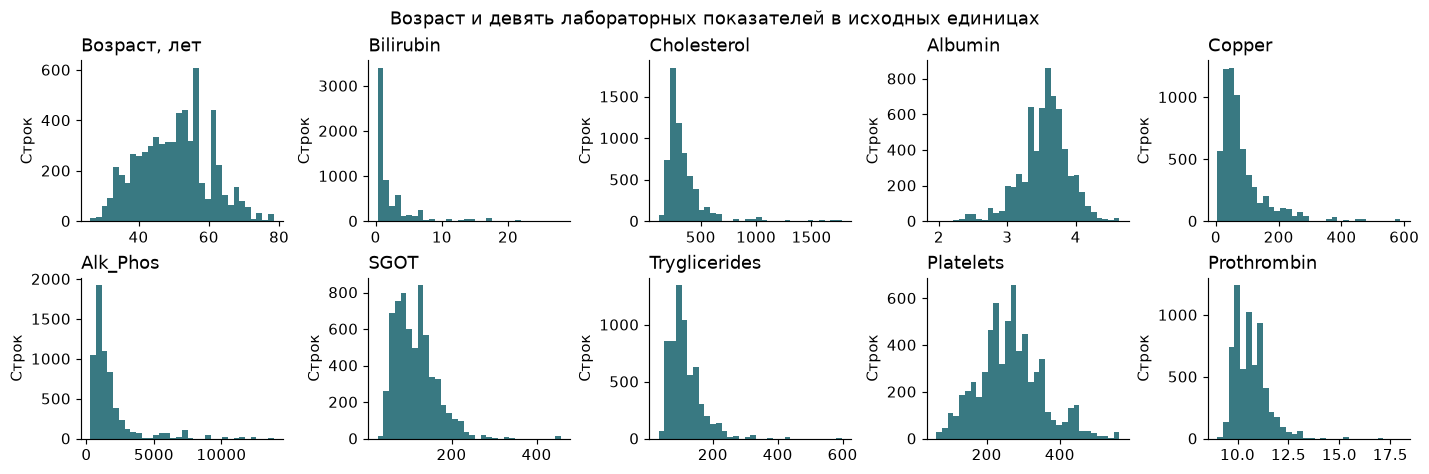

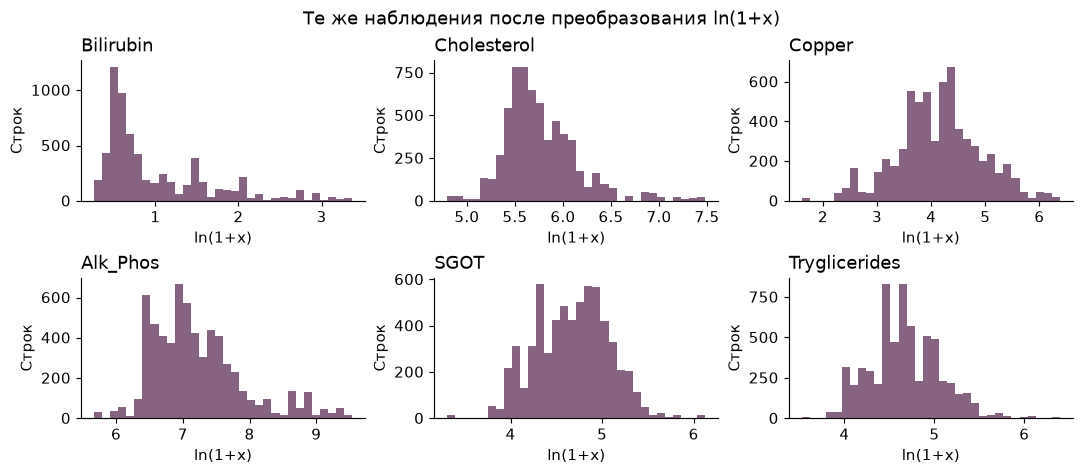

In [6]:
numeric = ["Age_years", *LABS]
measure = dev[LABS].assign(Age_years=dev.Age / 365.25)[numeric]
shape = measure.describe(percentiles=[.25, .5, .75]).T[["min","25%","50%","mean","75%","max"]]
shape["асимметрия"] = measure.skew()
shape["после log1p"] = np.log1p(measure[LOG_LABS]).skew()
display(shape.round(2))
fig, axes = plt.subplots(2, 5, figsize=(13.5, 4.4), layout="constrained")
fig.suptitle("Возраст и девять лабораторных показателей в исходных единицах")
for ax, name in zip(axes.flat, numeric):
    ax.hist(measure[name], bins=32, color="#397982")
    ax.set(title="Возраст, лет" if name == "Age_years" else name, ylabel="Строк")
plt.show()
fig, axes = plt.subplots(2, 3, figsize=(10.2, 4.4), layout="constrained")
fig.suptitle("Те же наблюдения после преобразования ln(1+x)")
for ax, name in zip(axes.flat, LOG_LABS):
    ax.hist(np.log1p(measure[name]), bins=32, color="#876382")
    ax.set(title=name, xlabel="ln(1+x)", ylabel="Строк")
plt.show()

У билирубина среднее заметно выше медианы. На обычной шкале основная масса строк сжата слева, после логарифма различия внутри этой группы видны лучше. Для оценки качества ещё понадобится модель. Асимметрия сама по себе не гарантирует выигрыш от преобразования.

### 3.2. Являются ли крайние значения ошибками

Сравним два правила разметки хвоста. Первое отделяет точки за 1,5 межквартильного размаха от границ ящика, второе — дальше трёх стандартных отклонений от среднего. Посмотрим также, к каким исходам относятся большие значения билирубина. Так можно оценить последствия автоматического удаления строк.

,"IQR, строк","IQR, %","|z| > 3, строк"
Alk_Phos,647,10.2,152
Bilirubin,633,10.0,196
Copper,541,8.6,122
Cholesterol,412,6.5,169
Tryglicerides,208,3.3,92
Prothrombin,143,2.3,55
Albumin,141,2.2,79
SGOT,114,1.8,61
Platelets,92,1.5,30
Age_years,30,0.5,0


Status,C,CL,D,"доля D, %"
Bilirubin,,,,
верхний хвост,104,14,515,81.4
остальные,3868,206,1617,28.4


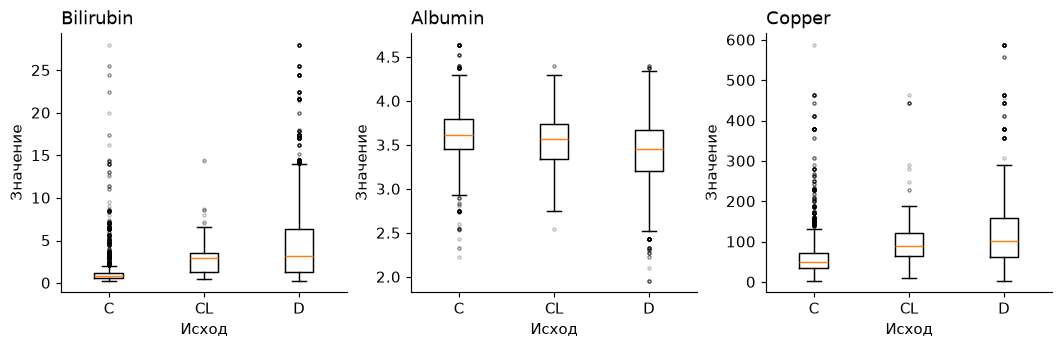

In [7]:
q1, q3 = measure.quantile(.25), measure.quantile(.75)
outside = measure.lt(q1 - 1.5*(q3-q1)) | measure.gt(q3 + 1.5*(q3-q1))
z_outside = ((measure - measure.mean()) / measure.std()).abs().gt(3)
tails = pd.DataFrame({"IQR, строк": outside.sum(), "IQR, %": 100*outside.mean(),
                      "|z| > 3, строк": z_outside.sum()}).sort_values("IQR, %", ascending=False)
display(tails.round(1))
tail = dev.Bilirubin.gt(q3.Bilirubin + 1.5*(q3.Bilirubin-q1.Bilirubin))
tail_table = pd.crosstab(tail.map({False: "остальные", True: "верхний хвост"}), dev.Status)[CLASSES]
tail_table["доля D, %"] = 100*tail_table.D / tail_table.sum(axis=1)
display(tail_table.round(1))
fig, axes = plt.subplots(1, 3, figsize=(10, 3.2), layout="constrained")
for ax, name in zip(axes, ["Bilirubin", "Albumin", "Copper"]):
    ax.boxplot([dev.loc[dev.Status.eq(c),name] for c in CLASSES], tick_labels=CLASSES,
               showfliers=True, flierprops={"markersize": 2, "alpha": .25})
    ax.set(title=name, xlabel="Исход", ylabel="Значение")
plt.show()

Два правила отмечают разное число строк. В верхнем хвосте билирубина доля `D` выше, и механическая обрезка убрала бы часть наблюдений с выраженным сигналом. Оставляем измерения. В продолжении сравним исходную шкалу, логарифм и масштабирование по медиане и межквартильному размаху.

## 4. Какие различия видны между группами

### 4.1. Частоты, доли исходов и размер связи

У редкой категории доля смерти может быть высокой, хотя она описывает лишь малую часть выборки. Поэтому для каждого уровня показываем и доли, и число строк. Критерий χ² проверяет гипотезу о независимости признака и трёх исходов, V Крамера описывает размер связи от 0 до 1. Для семи проверок вместе применяем поправку Бенджамини — Хохберга. В синтетической выборке эти оценки служат ориентиром для исследования.

In [8]:
associations, levels = [], []
for name in CATEGORICAL:
    tab = pd.crosstab(dev[name], dev.Status).reindex(columns=CLASSES, fill_value=0)
    chi2, p, _, expected = chi2_contingency(tab, correction=False)
    v = np.sqrt(chi2 / (tab.to_numpy().sum() * min(tab.shape[0]-1, tab.shape[1]-1)))
    associations.append([name, v, p, expected.min()])
    block = tab.div(tab.sum(axis=1), axis=0).mul(100)
    block.insert(0, "n", tab.sum(axis=1))
    block.index = pd.MultiIndex.from_arrays([[name]*len(block), tab.index], names=["признак", "уровень"])
    levels.append(block)
levels = pd.concat(levels)
display(levels.round(1))
assoc = pd.DataFrame(associations, columns=["признак","V Крамера","p","мин. ожидаемое n"])
assoc["p с поправкой"] = false_discovery_control(assoc.p)
display(assoc.sort_values("V Крамера", ascending=False).set_index("признак").style.format(
    {"V Крамера":"{:.3f}", "p":"{:.2g}", "мин. ожидаемое n":"{:.1f}", "p с поправкой":"{:.2g}"}))

Status                           n     C   CL     D
признак      уровень                               
Drug         D-penicillamine  3122  61.6  3.7  34.7
             Placebo          3202  64.0  3.3  32.7
Sex          F                5874  64.6  3.4  32.0
             M                 450  39.1  4.2  56.7
Ascites      N                6020  65.6  3.6  30.8
             Y                 304   6.6  1.3  92.1
Hepatomegaly N                3086  82.2  2.8  15.0
             Y                3238  44.3  4.2  51.5
Spiders      N                4780  71.8  3.2  25.0
             Y                1544  34.9  4.3  60.8
Edema        N                5725  67.7  3.6  28.7
             S                 327  27.5  3.7  68.8
             Y                 272   1.8  0.4  97.8
Stage        1.0               321  89.4  1.2   9.3
             2.0              1342  78.4  2.8  18.9
             3.0              2496  72.3  3.4  24.2
             4.0              2165  38.2  4.3  57.5

,V Крамера,p,мин. ожидаемое n,p с поправкой
признак,,,,
Hepatomegaly,0.396,1.5e-216,107.4,1e-215
Spiders,0.333,7.8e-153,53.7,1.4e-152
Ascites,0.278,1.1e-106,10.6,1.5e-106
Stage,0.269,1.5e-194,11.2,5.2e-194
Edema,0.243,5.8e-161,9.5,1.4e-160
Sex,0.138,9.7e-27,15.7,1.1e-26
Drug,0.025,0.13,108.6,0.13


У категорий `Edema` и `Ascites` состав исходов заметно меняется. У назначения препарата группы ближе друг к другу. Размер связи и численность помогают понять, почему маленькое p-значение, высокая доля `D` в подгруппе и полезность для прогноза всей выборки — три разных результата. По этим сравнениям нельзя оценить эффект лечения.

### 4.2. Что меняет сочетание отёков и асцита

Status            C   CL     D     n  доля D, %
Ascites Edema                                  
N       N      3859  205  1595  5659       28.2
        S        89   10   188   287       65.5
        Y         4    1    69    74       93.2
Y       N        18    2    46    66       69.7
        S         1    2    37    40       92.5
        Y         1    0   197   198       99.5

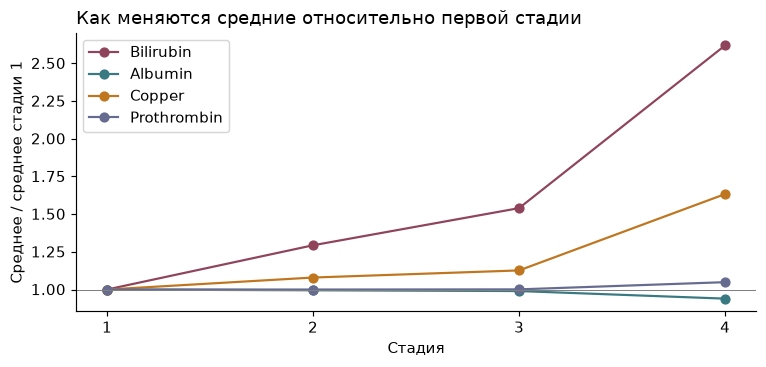

In [9]:
joint = pd.crosstab([dev.Ascites, dev.Edema], dev.Status).reindex(columns=CLASSES, fill_value=0)
joint["n"] = joint[CLASSES].sum(axis=1)
joint["доля D, %"] = 100*joint.D / joint.n
display(joint.round(1))
stage_means = dev.groupby("Stage")[["Bilirubin","Albumin","Copper","Prothrombin"]].mean()
ratio = stage_means.div(stage_means.iloc[0])
ax = ratio.plot(marker="o", figsize=(7.4,3.6), color=["#90445c","#397982","#bf761e","#666b90"])
ax.axhline(1, linewidth=.7, color="grey")
ax.set(xticks=stage_means.index, xlabel="Стадия", ylabel="Среднее / среднее стадии 1",
       title="Как меняются средние относительно первой стадии")
plt.tight_layout()
plt.show()

Сочетание асцита и сохраняющихся отёков выделяет небольшую группу с высокой долей `D`. По стадиям среднее значение билирубина меняется заметнее, чем среднее протромбиновое время. Для модели отсюда следуют две проверяемые идеи — добавить взаимодействие признаков осмотра и позволить каждой стадии иметь собственный эффект.

## 5. Что добавляет второй лабораторный показатель

Корреляция Спирмена сравнивает ранги, поэтому длинный хвост меньше влияет на результат, чем при линейной корреляции Пирсона. Сначала ищем показатели с похожим порядком значений. Затем смотрим, меняется ли доля `D` на плоскости билирубина и альбумина. Цвет присваиваем только ячейкам с десятью и более наблюдениями.

ρ Спирмена
Bilirubin   Copper       0.588
            SGOT         0.506
Copper      SGOT         0.447
Alk_Phos    SGOT         0.429
Cholesterol SGOT         0.352

,Bilirubin,Copper,Albumin,Cholesterol,Prothrombin
медианы по исходам,,,,,
C,0.8,50.0,3.62,288.0,10.4
CL,2.9,89.0,3.57,333.0,10.6
D,3.2,101.0,3.46,331.0,11.0


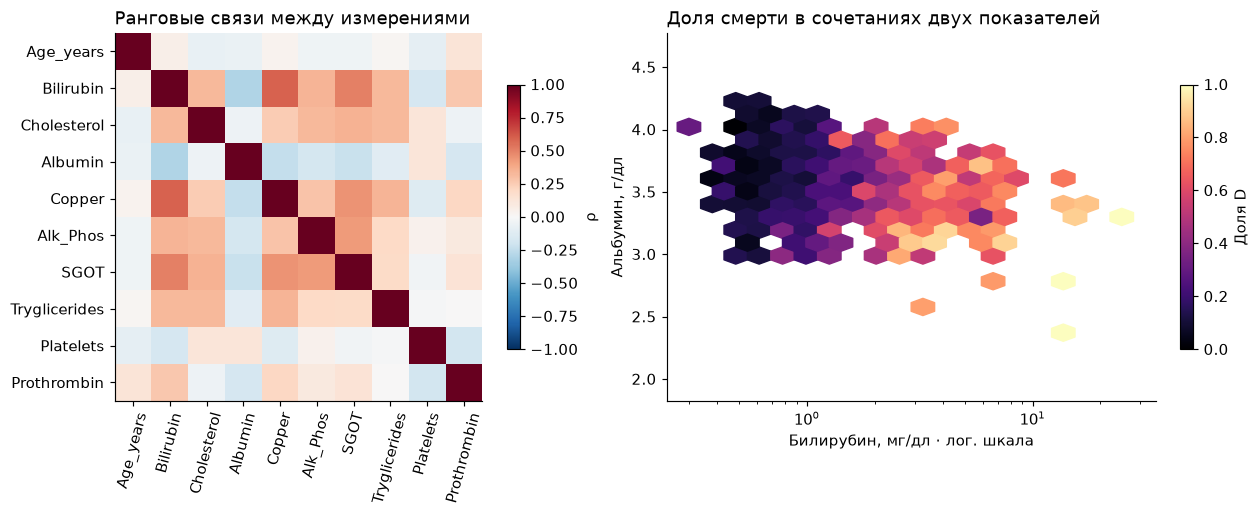

In [10]:
corr = measure.corr(method="spearman")
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), 1)).stack()
display(pairs.loc[pairs.abs().nlargest(5).index].rename("ρ Спирмена").to_frame().round(3))
display(dev.groupby("Status")[["Bilirubin","Copper","Albumin","Cholesterol","Prothrombin"]]
        .median().reindex(CLASSES).rename_axis("медианы по исходам"))
fig, (ax, bx) = plt.subplots(1, 2, figsize=(12.2,4.8), layout="constrained")
im = ax.imshow(corr, vmin=-1, vmax=1, cmap="RdBu_r")
ax.set(xticks=range(len(corr)), yticks=range(len(corr)), xticklabels=corr.columns,
       yticklabels=corr.index, title="Ранговые связи между измерениями")
ax.tick_params(axis="x", labelrotation=75)
fig.colorbar(im, ax=ax, shrink=.72, label="ρ")
hexbins = bx.hexbin(dev.Bilirubin, dev.Albumin, C=dev.Status.eq("D"), xscale="log",
                    gridsize=(19,13), mincnt=10, reduce_C_function=np.mean, cmap="magma", vmin=0, vmax=1)
bx.set(xlabel="Билирубин, мг/дл · лог. шкала", ylabel="Альбумин, г/дл",
       title="Доля смерти в сочетаниях двух показателей")
fig.colorbar(hexbins, ax=bx, shrink=.72, label="Доля D")
plt.show()

Билирубин и медь дают частично сходную информацию. У альбумина направление связи иное. На совместной карте высокие доли смерти сосредоточены преимущественно при повышенном билирубине. Границы между исходами размыты. Проверим на фолдах, сколько удаётся добавить к прогнозу по одному билирубину.

## 6. Почему длительность наблюдения требует отдельного опыта

`N_Days` становится известен при завершении наблюдения. Он может статистически различать группы, но пользоваться им в день обследования невозможно. Сравним срок по трём статусам и посмотрим на связь с индикатором каждого класса. Такая запись сохраняет смысл `CL` как отдельной категории.

,10-й процентиль,медиана,90-й процентиль,ρ с индикатором класса
Status,,,,
C,1216.0,2195.0,3933.0,0.379
CL,736.6,1431.5,2573.0,-0.080
D,264.0,1212.0,3297.0,-0.357


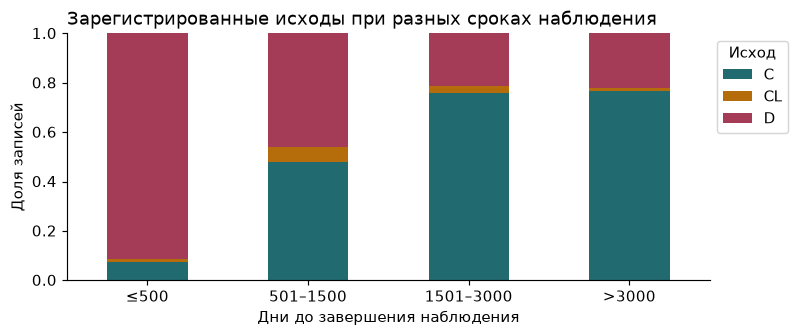

In [11]:
duration = dev.groupby("Status").N_Days.quantile([.1,.5,.9]).unstack().reindex(CLASSES)
duration.columns = ["10-й процентиль","медиана","90-й процентиль"]
duration["ρ с индикатором класса"] = [
    dev.N_Days.corr(dev.Status.eq(c).astype(int), method="spearman") for c in CLASSES
]
display(duration.round(3))
period = pd.cut(dev.N_Days, [-np.inf,500,1500,3000,np.inf], labels=["≤500","501–1500","1501–3000",">3000"])
tab = pd.crosstab(period, dev.Status).reindex(columns=CLASSES)
rate = tab.div(tab.sum(axis=1), axis=0)
ax = rate.plot.bar(stacked=True, rot=0, color=[COLORS[c] for c in CLASSES], figsize=(7.7,3.3))
ax.set(title="Зарегистрированные исходы при разных сроках наблюдения",
       ylabel="Доля записей", xlabel="Дни до завершения наблюдения", ylim=(0,1))
ax.legend(title="Исход", loc="upper left", bbox_to_anchor=(1,1))
plt.tight_layout()
plt.show()

Короткие сроки чаще заканчиваются записью `D`. Во всех диапазонах встречаются разные исходы, а срок включает время до самого события. В основной модели остаются только признаки, доступные на входе. В продолжении измерим, насколько меняется та же модель, если разрешить ей видеть длительность наблюдения.

## 7. Сколько информации несёт один признак и что даёт второй

Разобьём числовой показатель на интервалы по обучающей части каждого фолда. Внутри интервала посчитаем частоты трёх исходов и добавим по одному условному наблюдению каждого класса, чтобы избежать нулевых вероятностей. Например, десять `C`, один `CL` и четыре `D` дадут вероятности 11/18, 2/18 и 5/18. Для новой комбинации интервалов используем частоты обучающей части. Оценку log loss считаем на отложенном фолде.

In [12]:
def interval_keys(fit, valid, columns, n_bins):
    fit_keys, valid_keys = {}, {}
    for name in columns:
        if name in CATEGORICAL:
            fit_keys[name], valid_keys[name] = fit[name], valid[name]
        else:
            edges = np.unique(np.quantile(fit[name], np.linspace(0, 1, n_bins+1)))
            cuts = edges[1:-1]
            fit_keys[name] = np.searchsorted(cuts, fit[name], side="left")
            valid_keys[name] = np.searchsorted(cuts, valid[name], side="left")
    return pd.DataFrame(fit_keys, index=fit.index), pd.DataFrame(valid_keys, index=valid.index)

def binned_score(columns, n_bins):
    losses = []
    for i, j in folds:
        fit, valid = dev.iloc[i], dev.iloc[j]
        priors = fit.Status.value_counts(normalize=True).reindex(CLASSES).to_numpy()
        if columns:
            fk, vk = interval_keys(fit, valid, columns, n_bins)
            counts = (fk.assign(outcome=fit.Status).groupby(columns + ["outcome"])
                      .size().unstack(fill_value=0).reindex(columns=CLASSES, fill_value=0))
            probs = (counts+1).div(counts.sum(axis=1)+len(CLASSES), axis=0)
            p = vk.join(probs, on=columns)[CLASSES].fillna(dict(zip(CLASSES, priors))).to_numpy()
        else:
            p = np.tile(priors, (len(valid),1))
        assert np.allclose(p.sum(axis=1), 1)
        losses.append(log_loss(valid.Status, p, labels=CLASSES))
    return [np.mean(losses), np.std(losses, ddof=1)]

scores = {"Частоты классов": binned_score([], 10)}
scores.update({name: binned_score([name], 10) for name in [*PROFILE,"N_Days"]})
single = pd.DataFrame.from_dict(scores, orient="index", columns=["log loss","SD фолдов"])
display(single.sort_values("log loss").round(4))
combos = [["Bilirubin"], ["Bilirubin","Copper"], ["Bilirubin","Albumin"], ["Bilirubin","Hepatomegaly"]]
double = pd.DataFrame([binned_score(cols, 6) for cols in combos], columns=single.columns,
                      index=[" + ".join(cols) for cols in combos])
double["изменение к билирубину"] = double["log loss"] - double.iloc[0]["log loss"]
display(double.round(4))

,log loss,SD фолдов
Bilirubin,0.5980,0.0155
Copper,0.6541,0.0162
N_Days,0.6602,0.0093
Prothrombin,0.6882,0.0189
Hepatomegaly,0.6939,0.0093
Stage,0.7034,0.0082
SGOT,0.7066,0.0118
Edema,0.7154,0.0059
Spiders,0.7221,0.0099
Albumin,0.7312,0.0101


,log loss,SD фолдов,изменение к билирубину
Bilirubin,0.5991,0.0168,0.0000
Bilirubin + Copper,0.5861,0.0219,-0.0130
Bilirubin + Albumin,0.5966,0.0175,-0.0025
Bilirubin + Hepatomegaly,0.5773,0.0077,-0.0218


In [13]:
top = single.drop(index=["Частоты классов","N_Days"]).sort_values("log loss").index[:2]
pair = double["log loss"].idxmin()
display(Markdown(f"Лучшими одиночными входными показателями стали **{top[0]}** и **{top[1]}**. "
                 f"У {top[0]} log loss равен {single.loc[top[0], 'log loss']:.3f}, у прогноза по частотам — "
                 f"{single.loc['Частоты классов','log loss']:.3f}. В отдельном сравнении на шести интервалах "
                 f"минимум у **{pair}** ({double.loc[pair,'log loss']:.3f}). Все варианты пар "
                 "и их отправная точка используют одинаковую сетку, до шести интервалов на числовой признак."))

Лучшими одиночными входными показателями стали **Bilirubin** и **Copper**. У Bilirubin log loss равен 0.598, у прогноза по частотам — 0.776. В отдельном сравнении на шести интервалах минимум у **Bilirubin + Hepatomegaly** (0.577). Все варианты пар и их отправная точка используют одинаковую сетку, до шести интервалов на числовой признак.

## 8. Насколько похожи конкурсные train и test

Сравним средние в единицах стандартного отклонения train, доли всех категорий и эмпирические функции распределения. Такие проверки могут выявить заметный сдвиг входных данных. О качестве прогноза на test здесь судить нельзя, поскольку его исходы скрыты.

,"сдвиг среднего, SD"
Age,0.034
Albumin,-0.030
SGOT,-0.021
Platelets,-0.014
Copper,0.011
Cholesterol,0.010
N_Days,0.008
Prothrombin,0.004
Alk_Phos,-0.003
Bilirubin,0.002


,"максимальная разница долей, п.п."
Hepatomegaly,0.66
Stage,0.47
Drug,0.38
Sex,0.28
Edema,0.21
Ascites,0.18
Spiders,0.12


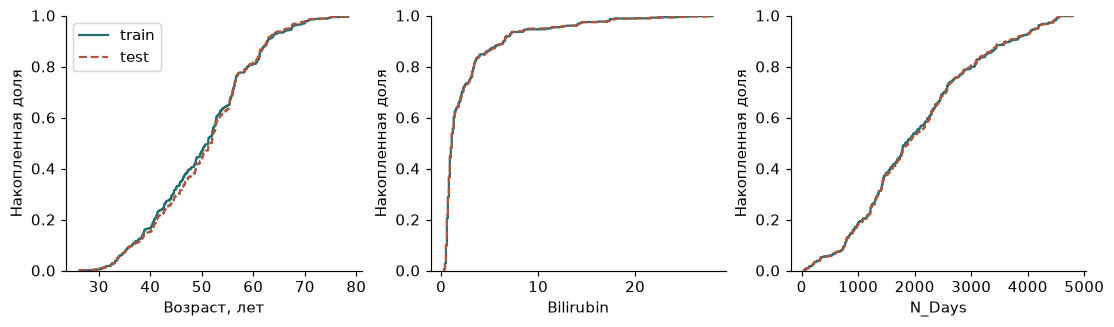

Наибольший сдвиг среднего у **Age** — 0.034 SD. Максимальный разрыв по доле отдельной категории — 0.66 п.п. На этих срезах распределения близки. Последовательные номера id говорят о нумерации, но не раскрывают способ генерации или хронологию записей.

In [14]:
drift_cols = ["Age", *LABS, "N_Days"]
shift = (test[drift_cols].mean() - train[drift_cols].mean()) / train[drift_cols].std()
display(shift.loc[shift.abs().sort_values(ascending=False).index].rename("сдвиг среднего, SD").round(3).to_frame())
cat_shift = {}
for name in CATEGORICAL:
    tr, te = train[name].value_counts(normalize=True).align(test[name].value_counts(normalize=True), fill_value=0)
    cat_shift[name] = (te-tr).abs().max()*100
display(pd.Series(cat_shift, name="максимальная разница долей, п.п.").sort_values(ascending=False).round(2).to_frame())
fig, axes = plt.subplots(1,3,figsize=(10.5,3.0),layout="constrained")
for ax, name in zip(axes, ["Age", "Bilirubin", "N_Days"]):
    for frame, label, color in [(train,"train","#246e72"),(test,"test","#ab563e")]:
        x = frame[name] / 365.25 if name=="Age" else frame[name]
        ax.ecdf(x, label=label, color=color, linestyle="-" if label=="train" else "--")
    ax.set(xlabel="Возраст, лет" if name=="Age" else name, ylabel="Накопленная доля")
axes[0].legend()
plt.show()
display(Markdown(f"Наибольший сдвиг среднего у **{shift.abs().idxmax()}** — {shift.abs().max():.3f} SD. "
                 f"Максимальный разрыв по доле отдельной категории — {max(cat_shift.values()):.2f} п.п. "
                 "На этих срезах распределения близки. Последовательные номера id говорят о нумерации, "
                 "но не раскрывают способ генерации или хронологию записей."))

## 9. Что переходит в моделирование

К началу прогноза доступны 17 полей. Сохраняем редкие категории и крайние измерения, кодируем стадии и признаки осмотра как категории. Для шести анализов проверяем логарифмирование, для билирубина, альбумина и меди — сочетания и нелинейную форму связи. Заполнение возможных пропусков, кодирование и масштабирование будем обучать внутри фолда.

Качество сравним с прогнозом по частотам. Редкий `CL` оставляет открытым практический вопрос — удастся ли находить больше трансплантаций без большого проигрыша в вероятностях. Ему посвящены опыты с весами, увеличением и уменьшением обучающих классов и порогом решения в `02_modeling.ipynb`.